In [1]:
import utils
import xarray as xr
import numpy as np
import dask
from distributed import Client
from dask.distributed import wait
from ncar_jobqueue import NCARCluster
from glob import glob
import intake
import importlib
import pop_tools
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
xr.set_options(keep_attrs=True)

## Spin up DASK cluster

In [2]:
def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=2,
        memory='100 GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=100GB',
        project='NCGD0011',
        walltime='02:00:00',
        interface='ext',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

In [3]:
cluster, client = get_ClusterClient()
cluster.scale(20) 
client

Client Scheduler: tcp://128.117.208.175:35421 Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Cluster Workers: 0 Cores: 0 Memory: 0 B


## Define some functions we'll need to load data

In [4]:
# function to return the variables we need to return for all metrics
def get_metric_variable(metric):
    var_names = metrics_dict[metric]
    # handle the case where there is only one variable
    if isinstance(var_names, str):
        return var_names
    # handle the case where there are multiple variables
    else:
        return var_names[:]

In [5]:
# function for loading datasets
def load_datasets(varnames, experiment):
    ds_list = []
    for varname in varnames:
        subset = catalog.search(component='ocn',
                                variable=varname,
                                experiment=experiment,
                                forcing_variant='cmip6',
                               )
        with dask.config.set(**{'array.slicing.split_large_chunks': True}):
            dsets = subset.to_dataset_dict(preprocess=preprocess)
        ds = dsets[f'ocn.{experiment}.pop.h.cmip6.{varname}'] 
        
        # compute time mean to get correct months
        ds['time']= ds.time_bound.compute().mean(dim="d2")
        # keep only some variables
        keep_vars=['z_t','time_bound','z_t_150m','KMT','TLAT','TLONG','time'] + [varname]
        ds = ds.drop([v for v in ds.variables if v not in keep_vars])
        ds_list.append(ds)
        ds = xr.merge(ds_list, compat="override")

    return ds

In [14]:
def preprocess(ds):
    ds=ds.isel(z_t=0)
    return ds

### get the ocean grid data

In [6]:
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG
area = ds_grid.TAREA
lons_norm = utils.normal_lons(lons)

## Select the metric you are interested in

In [7]:
import utils

In [8]:
## Enter the years you want to keep:
yy_st = "1850"
yy_ed = "2100"

## Load CESM2-LE data

In [9]:
varnames = ['TEMP']

### Load the Data Catalog

In [10]:
catalog = intake.open_esm_datastore(
    '/glade/collections/cmip/catalog/intake-esm-datastore/catalogs/glade-cesm2-le.json'
)

### Load historical data

In [15]:
%%time
# load historical
ds_hist = load_datasets(varnames,'historical')

ds_hist


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


CPU times: user 17.1 s, sys: 562 ms, total: 17.7 s
Wall time: 33.6 s


<xarray.Dataset>
Dimensions:     (d2: 2, member_id: 50, nlat: 384, nlon: 320, time: 1980, z_t_150m: 15)
Coordinates:
    z_t         float32 500.0
  * z_t_150m    (z_t_150m) float32 500.0 1.5e+03 2.5e+03 ... 1.35e+04 1.45e+04
    TLONG       (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    TLAT        (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
  * time        (time) object 1850-01-16 13:00:00.000001 ... 2014-12-16 12:00:00
Dimensions without coordinates: d2, member_id, nlat, nlon
Data variables:
    KMT         (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    time_bound  (time, d2) object dask.array<chunksize=(120, 2), meta=np.ndarray>
    TEMP        (member_id, time, nlat, nlon) float32 dask.array<chunksize=(1, 120, 384, 320), meta=np.ndarray>

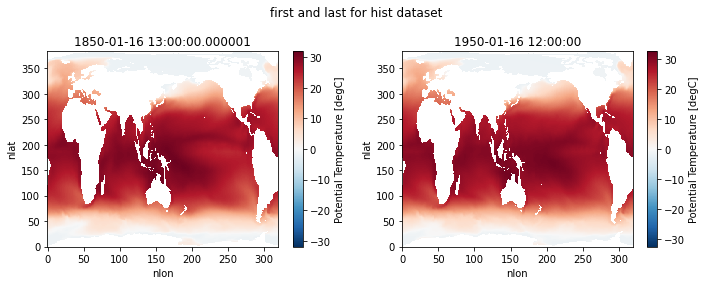

In [16]:
mem_5_hist = ds_hist.TEMP.isel(member_id=5)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

mem_5_hist.isel(time=0).plot(ax=ax1)
ax1.set_title(mem_5_hist.isel(time=0).time.values)

mem_5_hist.isel(time=1200).plot(ax=ax2)
ax2.set_title(mem_5_hist.isel(time=1200).time.values)

fig.suptitle("first and last for hist dataset")

plt.tight_layout()
plt.show()

### Load future data

In [17]:
%%time
# load historical
ds_ssp = load_datasets(varnames,'ssp370')
ds_ssp


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


CPU times: user 8.87 s, sys: 196 ms, total: 9.07 s
Wall time: 12.4 s


<xarray.Dataset>
Dimensions:     (d2: 2, member_id: 50, nlat: 384, nlon: 320, time: 1032, z_t_150m: 15)
Coordinates:
    z_t         float32 500.0
  * z_t_150m    (z_t_150m) float32 500.0 1.5e+03 2.5e+03 ... 1.35e+04 1.45e+04
    TLONG       (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    TLAT        (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
  * time        (time) object 2015-01-16 13:00:00.000001 ... 2100-12-16 12:00:00
Dimensions without coordinates: d2, member_id, nlat, nlon
Data variables:
    KMT         (nlat, nlon) float64 dask.array<chunksize=(384, 320), meta=np.ndarray>
    time_bound  (time, d2) object dask.array<chunksize=(120, 2), meta=np.ndarray>
    TEMP        (member_id, time, nlat, nlon) float32 dask.array<chunksize=(1, 120, 384, 320), meta=np.ndarray>

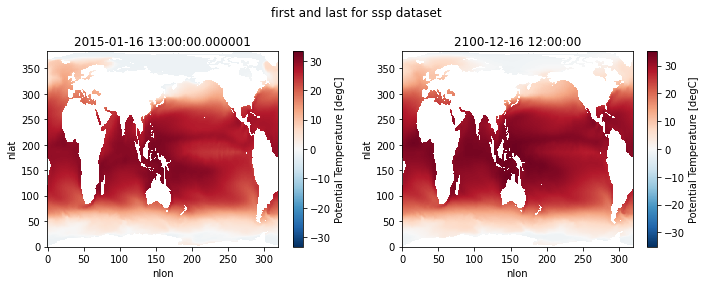

In [18]:
mem_5_ssp = ds_ssp.TEMP.isel(member_id=5)

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4))

mem_5_ssp.isel(time=0).plot(ax=ax1)
ax1.set_title(mem_5_ssp.isel(time=0).time.values)

mem_5_ssp.isel(time=-1).plot(ax=ax2)
ax2.set_title(mem_5_ssp.isel(time=-1).time.values)

fig.suptitle("first and last for ssp dataset")

plt.tight_layout()
plt.show()

## Concatenate historical and future datasets, keep just years of interest

In [19]:
ds = xr.concat((ds_hist, ds_ssp),dim='time')
ds.time

<xarray.DataArray 'time' (time: 3012)>
array([cftime.DatetimeNoLeap(1850, 1, 16, 13, 0, 0, 1),
       cftime.DatetimeNoLeap(1850, 2, 15, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(1850, 3, 16, 12, 0, 0, 0), ...,
       cftime.DatetimeNoLeap(2100, 10, 16, 12, 0, 0, 0),
       cftime.DatetimeNoLeap(2100, 11, 16, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(2100, 12, 16, 12, 0, 0, 0)], dtype=object)
Coordinates:
    z_t      float32 500.0
  * time     (time) object 1850-01-16 13:00:00.000001 ... 2100-12-16 12:00:00
Attributes:
    long_name:  boundaries for time-averaging interval

### Convert to annual means

In [20]:
ds = ds.resample({'time':'A'}).mean(dim='time').compute()

In [21]:
ds['time'] = np.arange(1850,2101,1)

### Do ToE analysis

In [22]:
time3d = np.full([251,384,320],1,dtype=int)

In [23]:
ylen = 384
xlen = 320

for x in np.arange(0,xlen,1):
    for y in np.arange(0,ylen,1):

        time3d[:,y,x]=ds.time.values

time3d = xr.DataArray(time3d,dims=('time','nlat','nlon'))

In [24]:
ds

<xarray.Dataset>
Dimensions:   (member_id: 50, nlat: 384, nlon: 320, time: 251, z_t_150m: 15)
Coordinates:
  * time      (time) int64 1850 1851 1852 1853 1854 ... 2096 2097 2098 2099 2100
    z_t       float32 500.0
  * z_t_150m  (z_t_150m) float32 500.0 1.5e+03 2.5e+03 ... 1.35e+04 1.45e+04
    TLONG     (nlat, nlon) float64 320.6 321.7 322.8 323.9 ... 318.9 319.4 319.8
    TLAT      (nlat, nlon) float64 -79.22 -79.22 -79.22 ... 72.2 72.19 72.19
Dimensions without coordinates: member_id, nlat, nlon
Data variables:
    KMT       (time, nlat, nlon) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    TEMP      (time, member_id, nlat, nlon) float32 nan nan nan ... nan nan nan

In [25]:
%%time

#HISTORICAL PERIOD = 1850 - 1899 (50 years)

upthres_ds = xr.Dataset()
lothres_ds = xr.Dataset()

variables=['TEMP']

for var in variables:
    
    ### calculate                                                                                                                                                                                                                                                                 
    mean_var = ds[var].isel(time=slice(0,50)).mean(dim=('time','member_id'))
    std_var = ds[var].isel(time=slice(0,50)).std(dim=('member_id','time'))
    
    var_array_upthres = mean_var + 2 * std_var
    var_array_lothres = mean_var - 2 * std_var

    upthres_ds[var] = var_array_upthres
    lothres_ds[var] = var_array_lothres

CPU times: user 1.15 s, sys: 323 ms, total: 1.47 s
Wall time: 1.47 s


In [26]:
ToE_up = time3d.where(ds.TEMP.mean(dim='member_id') > upthres_ds['TEMP'])
ToE_up = ToE_up.min(dim='time')

In [27]:
ToE_down = time3d.where(ds.TEMP.mean(dim='member_id') < lothres_ds['TEMP'])
ToE_down = ToE_down.min(dim='time')

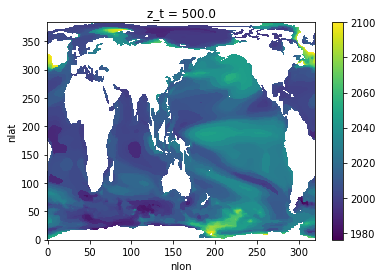

In [28]:
ToE_up.plot()

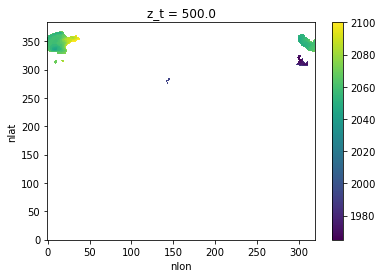

In [29]:
ToE_down.plot()

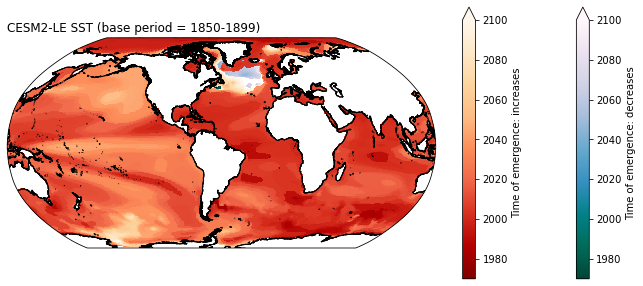

In [30]:
fig = plt.figure(figsize=(12,5))

############### 
ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))

ax.set_title('CESM2-LE SST (base period = 1850-1899)', loc='left')

lon,lat,field = utils.adjust_pop_grid(lons, lats, ToE_down)
pc = ax.pcolormesh(lon,lat,field,
                    transform=ccrs.PlateCarree(),cmap='PuBuGn_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: decreases');

lon,lat,field = utils.adjust_pop_grid(lons, lats, ToE_up)
pc = ax.pcolormesh(lon,lat,field,
                    transform=ccrs.PlateCarree(),cmap='OrRd_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: increases');

#fig.savefig('/glade/work/kristenk/figs/CESM2-LE-ToE-marine_NPP.png', bbox_inches='tight', dpi=300, format='png');

### Make a global timeseries

In [31]:
sst = ds.TEMP
area_masked = area.where(ds_grid.REGION_MASK > 0)

glb_sst = (sst * area_masked).sum(dim=('nlon','nlat'))/ area_masked.sum(dim=('nlon','nlat'))

In [34]:

#SIZ
mean = glb_sst.isel(time=slice(0,50)).mean(dim=('time','member_id')).values
std = glb_sst.isel(time=slice(0,50)).std(dim=('time','member_id')).values
toe_sst = glb_sst.time.where(glb_sst.mean(dim='member_id') > mean+2*std).min(dim='time').squeeze()
toe_sst_val = mean+2*std
print(toe_sst, toe_sst_val)

<xarray.DataArray 'time' ()>
array(1982.)
Coordinates:
    z_t      float32 500.0 18.555120249207313


In [37]:
toe_sst_val

18.555120249207313

Text(0.5, 0, 'Year')

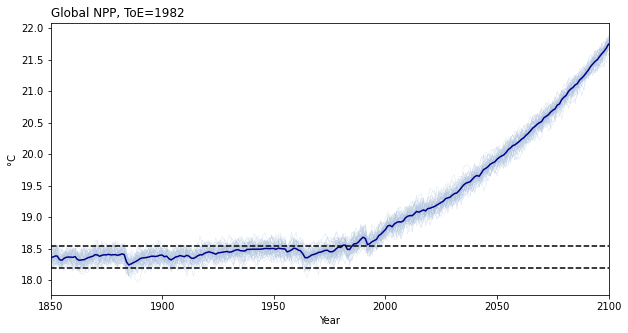

In [38]:
fig = plt.figure(figsize=(10,5))

#################
ax = fig.add_subplot(1, 1, 1)
ax.set_title("Global NPP, ToE=1982", loc="left", fontsize=12)

for mem in np.arange(0,50,1):

    ax.plot(glb_sst.time, glb_sst.isel(member_id=mem), color='lightsteelblue',linewidth=0.2)
    
ax.plot(glb_sst.time, glb_sst.mean(dim='member_id'),
           color='darkblue', zorder=2)
std_up = (glb_sst.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time')+ 2*glb_sst.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
std_down = (glb_sst.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time')- 2*glb_sst.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
ax.axhline(std_up, linestyle='--',color='black')
ax.axhline(std_down, linestyle='--',color='black')
ax.set_xlim(1850,2100)
#ax.set_ylim(13,20)
ax.set_ylabel('°C')
ax.set_xlabel('Year')

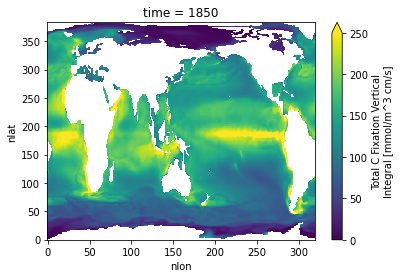

In [34]:
npp.isel(member_id=0,time=0).plot(vmin=0,vmax=250)

### Get data ready for writing out

In [39]:
ds_out = xr.Dataset()

ds_out['SST_ens_mean'] = ds['TEMP'].mean(dim='member_id')
ds_out['SST_ens_mean'].attrs = ds.TEMP.attrs
ds_out['SST_ens_mean'].attrs['units'] = 'deg C'
ds_out['SST_ens_mean'].attrs['notes'] = 'ensemble mean of 50 cmip6 forcing ensemble members'

ds_out['SST_st_dev'] = ds['TEMP'].std(dim='member_id')
ds_out['SST_st_dev'].attrs = ds.TEMP.attrs
ds_out['SST_st_dev'].attrs['units'] = 'deg C'
ds_out['SST_st_dev'].attrs['notes'] = 'ensemble standard deviation of 50 cmip6 forcing ensemble members'

ds_out.attrs['author'] = 'Kristen Krumhardt'
ds_out.attrs['date_processed'] = datetime.now().strftime('%Y-%m-%d')
ds_out.attrs['contents'] = f'Marine SST from CESM2-LE'

ds_out

<xarray.Dataset>
Dimensions:       (nlat: 384, nlon: 320, time: 251)
Coordinates:
  * time          (time) int64 1850 1851 1852 1853 1854 ... 2097 2098 2099 2100
    z_t           float32 500.0
    TLONG         (nlat, nlon) float64 320.6 321.7 322.8 ... 318.9 319.4 319.8
    TLAT          (nlat, nlon) float64 -79.22 -79.22 -79.22 ... 72.2 72.19 72.19
Dimensions without coordinates: nlat, nlon
Data variables:
    SST_ens_mean  (time, nlat, nlon) float32 nan nan nan nan ... nan nan nan nan
    SST_st_dev    (time, nlat, nlon) float32 nan nan nan nan ... nan nan nan nan
Attributes:
    author:          Kristen Krumhardt
    date_processed:  2026-10-29
    contents:        Marine SST from CESM2-LE

In [40]:
# calculate the size of the dataset in GB
size_gb = ds_out.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 0.23 GB.


In [41]:
path_out = '/glade/derecho/scratch/kristenk/ToE_saved_data/'
file_out = 'CESM2-LE-SST_ens_mean_std.nc'
fout = path_out + file_out

In [42]:
# Export the dataset to NetCDF with all attributes and coordinates
ds_out.to_netcdf(fout)